# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 02 against the shared **union** control pool and graph-smoothed.
Here we render them as deliverables and evaluate **Gate 2**.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom into *distinct
arms* out of a co-expression hub. A non-branching manifold instead shows a **single developmental
gradient** along the trajectory. In Zilionis 2019 that gradient is the **gastrulation →
somitogenesis** axis: Gast is high at the low-pseudotime origin and falls (rho ≈ −0.58) while pSom
rises to the terminus (rho ≈ +0.77; pSom-high decile at pseudotime 0.99), the two being strongly
anti-correlated in space (r ≈ −0.53, near Puram's −0.49 hub anchor) yet **not co-expressed**
(joint-high enrichment 0.73 < 1 — mutually exclusive, so one axis, not a hub). Neural crest does
**not** behave as the clean terminal readout the model expects: it is **globally depleted** (every
cell scores negative) and forms a shallow but statistically significant **U along pseudotime** —
marginally higher at *both* the Gast origin and the pSom terminus, lowest mid-trajectory
(quadratic t² > 0, permutation p < 0.001; amplitude ≈ 0.009, small against the score spread). Its
near-zero monotone rho reflects this symmetry, not a mid-axis peak. So Crest is a **weak, poorly
resolved third program** here, a genuine departure from the reference (where Crest is terminal on
the pSom arm) — a **flag** on Gate 2, not a reversal. The single-axis Gast→pSom gradient with
organised cross-repression **is present**, so **Gate 2 = GO (Crest-flagged)**; with no
co-expression hub / bifurcation the cross-repression test is **Gate 3 = NA** (the Wu 2021
organised-cross-repression-as-non-branching case).

**The gate is geography, not means.** The raw module means here (Gast −0.009 / pSom +0.039 /
Crest −0.023) are pSom-dominant with the other two negative — the common lung/PDAC profile. What
decides GO is the *geography*: a coherent Gast→pSom axis with organised cross-repression. The gate
is decided on the manifold geometry, not the scalar means. Deliverable: `signatures.h5ad`,
`{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0], '| scores present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 3920 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature: (i) the dominant developmental contrast is
Gast vs pSom (strong spatial anti-correlation) with **no co-expression** (joint-high enrichment
< 1 → one axis, not a hub); (ii) along pseudotime Gast declines and pSom rises; (iii) Crest is a
mutually-exclusive third territory. A co-expression hub (Puram) would show enrichment > 1.

In [4]:
def enrich(m1,m2):
    z1=(adata.obs[m1]-adata.obs[m1].mean())/adata.obs[m1].std()
    z2=(adata.obs[m2]-adata.obs[m2].mean())/adata.obs[m2].std()
    j=((z1>0.5)&(z2>0.5)).mean(); e=(z1>0.5).mean()*(z2>0.5).mean()
    return j/e if e>0 else np.nan
print('co-expression enrichment (>1 = hub, <1 = mutually exclusive):')
for x,y in [('Gast','pSom'),('Gast','Crest'),('pSom','Crest')]:
    print(f'  {x}&{y}-high: {enrich(x,y):.2f}')
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r=np.corrcoef(adata.obs[a],adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t=adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_=spearmanr(t,adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
for m,lab in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi=adata.obs[m]>=adata.obs[m].quantile(0.9)
    print(f'{lab}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
# Crest shape: mid-axis peak vs U (high both ends)? decile means + quadratic + permutation test
crest=adata.obs['Crest_sm'].values
early=tn<=0.15; mid=(tn>0.35)&(tn<0.65); late=tn>=0.85
print(f'Crest_sm  early(pt<=.15)={crest[early].mean():+.4f}  mid(.35-.65)={crest[mid].mean():+.4f}  late(pt>=.85)={crest[late].mean():+.4f}')
c2=np.polyfit(tn,crest,2)[0]
rng=np.random.default_rng(0); null=[np.polyfit(tn,rng.permutation(crest),2)[0] for _ in range(2000)]
pU=(np.abs(null)>=abs(c2)).mean()
print(f'Crest_sm quadratic t^2 = {c2:+.4f} (>0 => U: high at BOTH ends, lowest mid); permutation p = {pU:.4f}')
print(f'Crest is globally depleted (all cells negative: range [{crest.min():+.3f},{crest.max():+.3f}]) and only weakly U-shaped -> a poorly-resolved 3rd program, FLAG on Gate 2 (not the reference terminal readout)')
print('Gate 2: single Gast->pSom gradient + organised cross-repression (no co-expression hub) -> GO (Crest-flagged, non-branching)')
print('Gate 3: no co-expression hub / bifurcation -> NA')

co-expression enrichment (>1 = hub, <1 = mutually exclusive):
  Gast&pSom-high: 0.73
  Gast&Crest-high: 0.40
  pSom&Crest-high: 0.37
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.53
  Crest_sm vs Gast_sm: r = -0.51
  Crest_sm vs pSom_sm: r = -0.36
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.583
  pSom_sm: rho = +0.767
  Crest_sm: rho = +0.007
Gastrulation-high decile mean pseudotime = 0.15
Somitogenesis-high decile mean pseudotime = 0.99
Neural-crest-high decile mean pseudotime = 0.55
Crest_sm  early(pt<=.15)=-0.0204  mid(.35-.65)=-0.0289  late(pt>=.85)=-0.0193
Crest_sm quadratic t^2 = +0.0386 (>0 => U: high at BOTH ends, lowest mid); permutation p = 0.0000
Crest is globally depleted (all cells negative: range [-0.036,-0.008]) and only weakly U-shaped -> a poorly-resolved 3rd program, FLAG on Gate 2 (not the reference terminal readout)
Gate 2: single Gast->pSom gradient + organised cross-repression (no co-expression hub) -> GO (Cr

### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, plasma, **raw**
(not smoothed) score per cell so inDrop dropout is visible. Colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


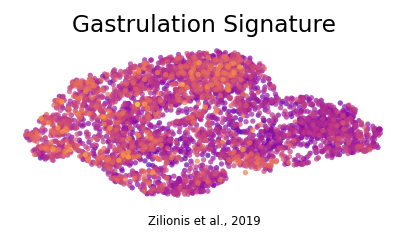

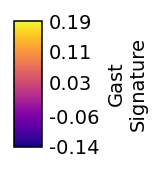

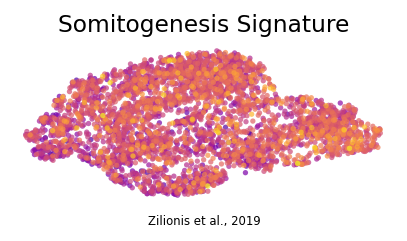

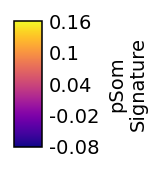

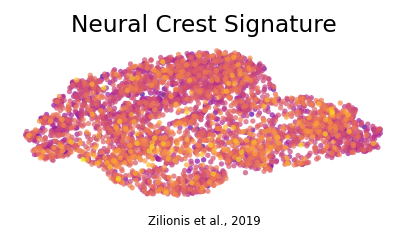

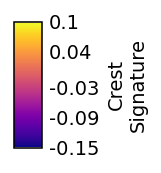

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')
plt.show()

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (3920, 28282)
